# Pregunta 1 Eliminacion de ruido periodico mediante filtrado notch

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

## 1. Implementacion: carga y configuracion

La imagen `P1.CR2` la convertimos a escala de grises y normalizamos en `[0, 1]`. Las posiciones de los notches se expresan como desplazamientos `(u, v)` respecto del centro del espectro. Al usar pares simetricos se modela la simetria producida por un ruido sinusoidal

Tamano original: (1504, 2256); rango: [0.180, 1.000]
Pares de notches: [(1058, 0)]; padding elegido: (32, 32) pixeles por borde


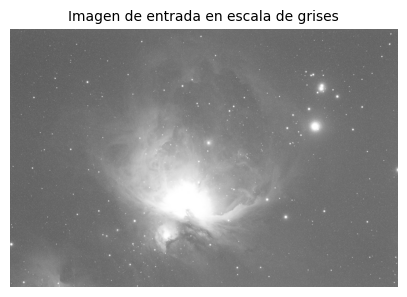

In [2]:
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["image.cmap"] = "gray"
plt.rcParams["axes.titlesize"] = 10

IMG_PATH = Path("img/P1.CR2")
image = np.asarray(Image.open(IMG_PATH).convert("L"), dtype=np.float64) / 255.0

NOTCH_PAIRS = [(1058, 0)]
DEFAULT_PADDING = (32, 32)

print(f"Tamano original: {image.shape}; rango: [{image.min():.3f}, {image.max():.3f}]")
print(f"Pares de notches: {NOTCH_PAIRS}; padding elegido: {DEFAULT_PADDING} pixeles por borde")
plt.figure(figsize=(5, 5))
plt.imshow(image, vmin=0, vmax=1)
plt.title("Imagen de entrada en escala de grises")
plt.axis("off");

## 2. Implementacion: padding, coordenadas y filtros notch

El padding usado es por reflexion (`reflect`) que genera una continuacion espejo de la imagen en cada borde, despues de la IFFT se recortan los mismos pixeles agregados.

El filtro ideal elimina un disco de radio `width` alrededor de cada centro, el filtro Gaussiano atenua suavemente segun `sigma` -> su respuesta es cercana a cero en el centro y aumenta hacia uno.

In [3]:
def pad_reflect(x, padding):
    """Extiende con reflexion; padding=(vertical, horizontal)."""
    py, px = padding
    return np.pad(x, ((py, py), (px, px)), mode="reflect")


def crop_padding(x, padding):
    py, px = padding
    y_end = x.shape[0] - py if py else x.shape[0]
    x_end = x.shape[1] - px if px else x.shape[1]
    return x[py:y_end, px:x_end]


def frequency_coordinates(shape):
    """Coordenadas enteras, con frecuencia cero en el centro."""
    h, w = shape
    v = np.arange(-h // 2, h - h // 2)
    u = np.arange(-w // 2, w - w // 2)
    U, V = np.meshgrid(u, v)
    return U, V


def notch_reject(shape, pairs, kind="ideal", width=1.0):
    """Construye H(u,v) para uno o mas pares de notches simetricos."""
    U, V = frequency_coordinates(shape)
    H = np.ones(shape, dtype=np.float64)
    for u0, v0 in pairs:
        for uc, vc in ((u0, v0), (-u0, -v0)):
            d2 = (U - uc) ** 2 + (V - vc) ** 2
            if kind == "ideal":
                H[d2 <= width ** 2] = 0.0
            elif kind == "gaussian":
                H *= 1.0 - np.exp(-d2 / (2.0 * width ** 2))
            else:
                raise ValueError("kind debe ser 'ideal' o 'gaussian'")
    return H


def scaled_notch_pairs(original_shape, padding, pairs=NOTCH_PAIRS):
    """Ajusta los centros para el tamano del espectro despues del padding."""
    py, px = padding
    h0, w0 = original_shape
    h, w = h0 + 2 * py, w0 + 2 * px
    return [(int(round(u * w / w0)), int(round(v * h / h0))) for u, v in pairs]


def apply_notch(x, pairs=None, kind="gaussian", width=2.0, padding=DEFAULT_PADDING):
    """FFT -> mascara notch -> IFFT -> recorte."""
    x_pad = pad_reflect(x, padding)
    if pairs is None:
        pairs = scaled_notch_pairs(x.shape, padding)
    F = np.fft.fftshift(np.fft.fft2(x_pad))
    H = notch_reject(x_pad.shape, pairs, kind=kind, width=width)
    filtered_pad = np.real(np.fft.ifft2(np.fft.ifftshift(H * F)))
    return crop_padding(filtered_pad, padding), F, H, H * F


def log_spectrum(F):
    return np.log1p(np.abs(F))

print("Funciones listas:", "pad_reflect", "crop_padding", "notch_reject", "apply_notch")


Funciones listas: pad_reflect crop_padding notch_reject apply_notch


## 3. Experimentacion: espectro e identificacion de las componentes

Se muestra el espectro logaritmico con frecuencia cero al centro, las marcas indican las componentes que atribuimos al patron periodico. En esta imagen se observan picos conjugados en `(+-1058, 0)`, asociados a las bandas verticales, que se atenuan con el notch seleccionado. Se usan coordenadas relativas al centro para que la seleccion sea independiente del tamano de la imagen.

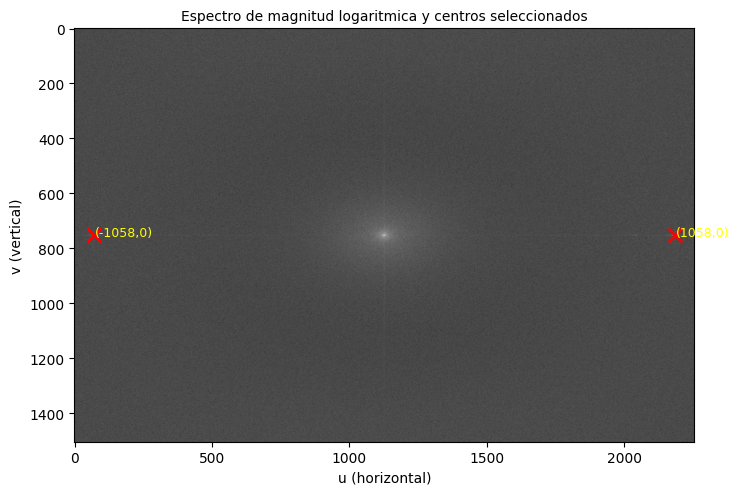

Los pares seleccionados son simetricos respecto del centro:  [(1058, 0)]


In [4]:
F0 = np.fft.fftshift(np.fft.fft2(image))
spec0 = log_spectrum(F0)
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(spec0)
cy, cx = np.array(spec0.shape) // 2
for u0, v0 in NOTCH_PAIRS:
    for u, v in ((u0, v0), (-u0, -v0)):
        ax.plot(cx + u, cy + v, "rx", ms=10, mew=2)
        ax.text(cx + u + 3, cy + v + 3, f"({u},{v})", color="yellow", fontsize=9)
ax.set_title("Espectro de magnitud logaritmica y centros seleccionados")
ax.set_xlabel("u (horizontal)"); ax.set_ylabel("v (vertical)");
plt.show()
print("Los pares seleccionados son simetricos respecto del centro: ", NOTCH_PAIRS)

## 4. Experimentacion: comparacion sistematica de anchos

Se prueban varios anchos para ambas familias, en los casos principales se muestran la imagen filtrada, el espectro antes y despues y la diferencia `ruidosa - filtrada`. La misma escala `[0, 1]` se usa para todas las imagenes y una escala comun se usa para las diferencias.

ideal  | width, std(diferencia), media(abs(diferencia))
   1.0 -> 0.01576, 0.01370
   2.0 -> 0.01702, 0.01455
   3.0 -> 0.01741, 0.01496
   5.0 -> 0.01771, 0.01532
gaussian  | width, std(diferencia), media(abs(diferencia))
   1.0 -> 0.01261, 0.01112
   2.0 -> 0.01534, 0.01334
   3.0 -> 0.01636, 0.01422
   5.0 -> 0.01715, 0.01492


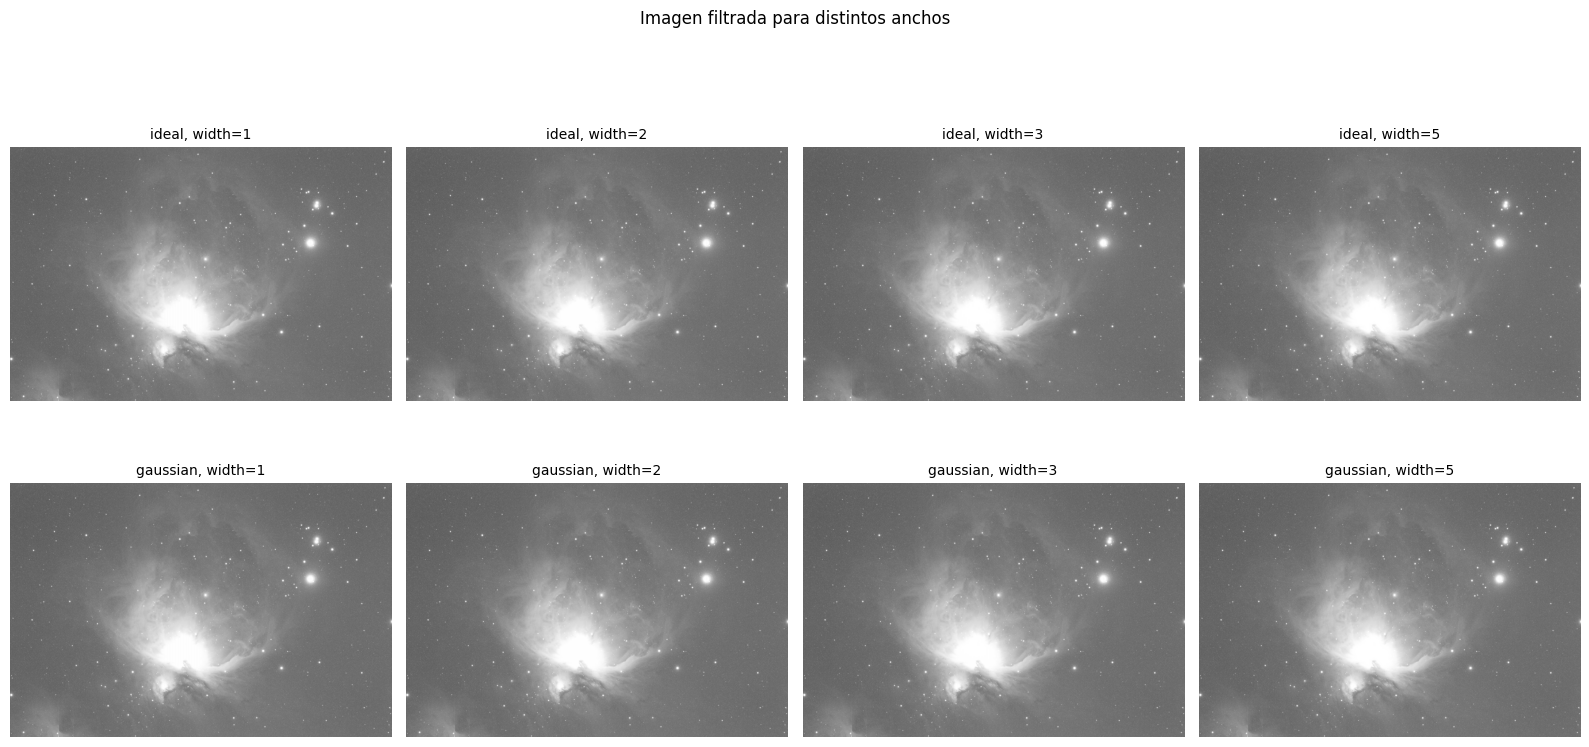

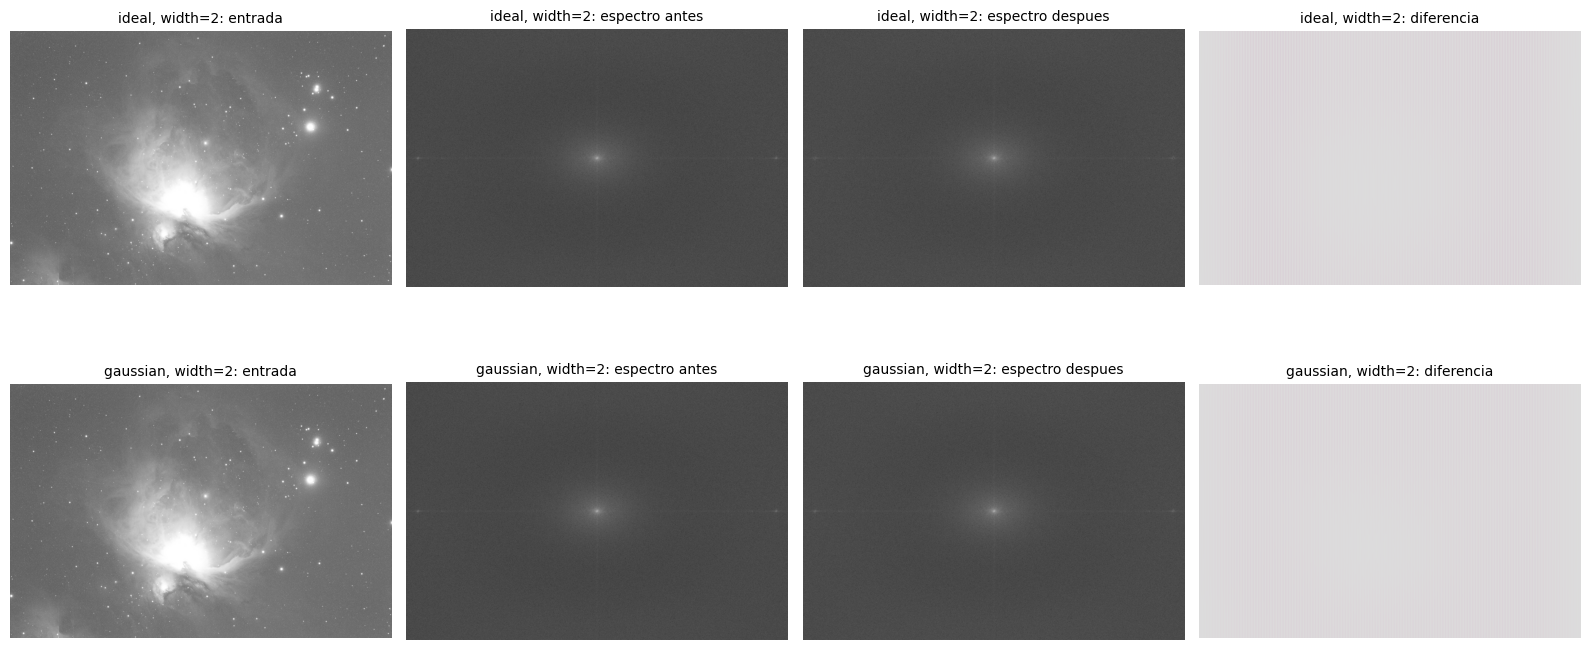

In [5]:
widths = [1.0, 2.0, 3.0, 5.0]
results = {}
for kind in ("ideal", "gaussian"):
    rows = []
    for width in widths:
        filtered, F, H, FF = apply_notch(image, kind=kind, width=width, padding=DEFAULT_PADDING)
        diff = image - filtered
        results[(kind, width)] = (filtered, F, H, FF, diff)
        rows.append((width, np.std(diff), np.mean(np.abs(diff))))
    print(kind, " | width, std(diferencia), media(abs(diferencia))")
    for row in rows:
        print(f"  {row[0]:4.1f} -> {row[1]:.5f}, {row[2]:.5f}")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for row, kind in enumerate(("ideal", "gaussian")):
    for col, width in enumerate(widths):
        filtered, F, H, FF, diff = results[(kind, width)]
        axes[row, col].imshow(filtered, vmin=0, vmax=1)
        axes[row, col].set_title(f"{kind}, width={width:g}")
        axes[row, col].axis("off")
plt.suptitle("Imagen filtrada para distintos anchos", y=1.02)
plt.tight_layout(); plt.show()

main_cases = [("ideal", 2.0), ("gaussian", 2.0)]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for row, (kind, width) in enumerate(main_cases):
    filtered, F, H, FF, diff = results[(kind, width)]
    vmax_diff = 0.18
    panels = [(image, "entrada"), (log_spectrum(F), "espectro antes"),
              (log_spectrum(FF), "espectro despues"), (diff, "diferencia")]
    for col, (data, title) in enumerate(panels):
        if title == "diferencia":
            axes[row, col].imshow(data, vmin=-vmax_diff, vmax=vmax_diff, cmap="coolwarm")
        elif title.startswith("espectro"):
            axes[row, col].imshow(data)
        else:
            axes[row, col].imshow(data, vmin=0, vmax=1)
        axes[row, col].set_title(f"{kind}, width={width:g}: {title}")
        axes[row, col].axis("off")
plt.tight_layout(); plt.show()


### Observacin de los anchos

Un ancho pequeno elimina principalmente la componente marcada y deja mas ruido residual. Al aumentar el ancho se atenuan frecuencias vecinas: el patron disminuye, pero tambien puede perderse textura y aparecer una diferencia mas extendida. El notch ideal cambia bruscamente en el borde, mientras que el Gaussiano produce una transicion mas gradual y normalmente menos artefactos de ringing.

## 5. Experimentacion: efecto del padding y analisis de bordes

Se comparan tres casos: sin padding, reflexion de 32 pixeles y reflexion de 64 pixeles por borde. Se mantiene fija la familia Gaussiana y `width=2`, para observar solo el efecto de la extension.

padding=(0, 0): std(diferencia)=0.01510, media(abs(diferencia))=0.01305
padding=(32, 32): std(diferencia)=0.01534, media(abs(diferencia))=0.01334
padding=(64, 64): std(diferencia)=0.01556, media(abs(diferencia))=0.01362


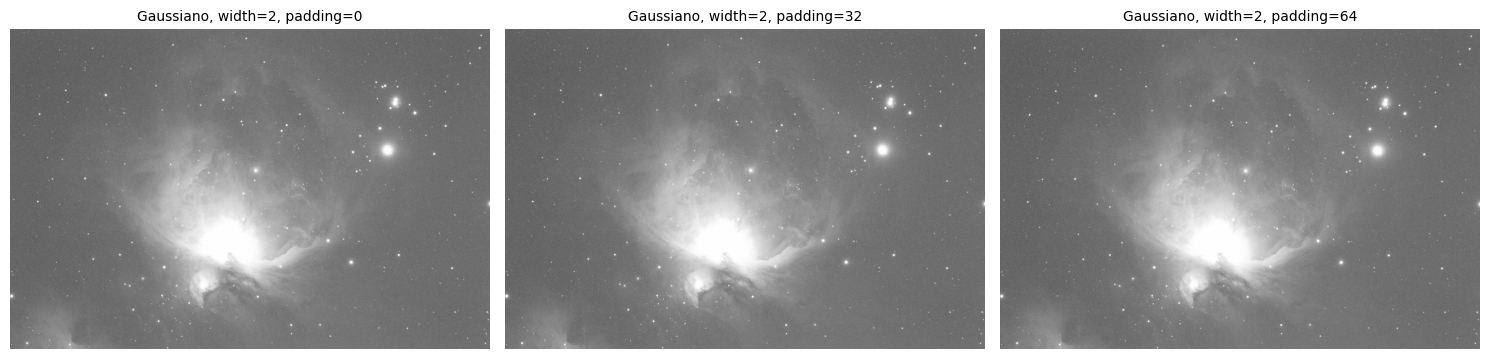

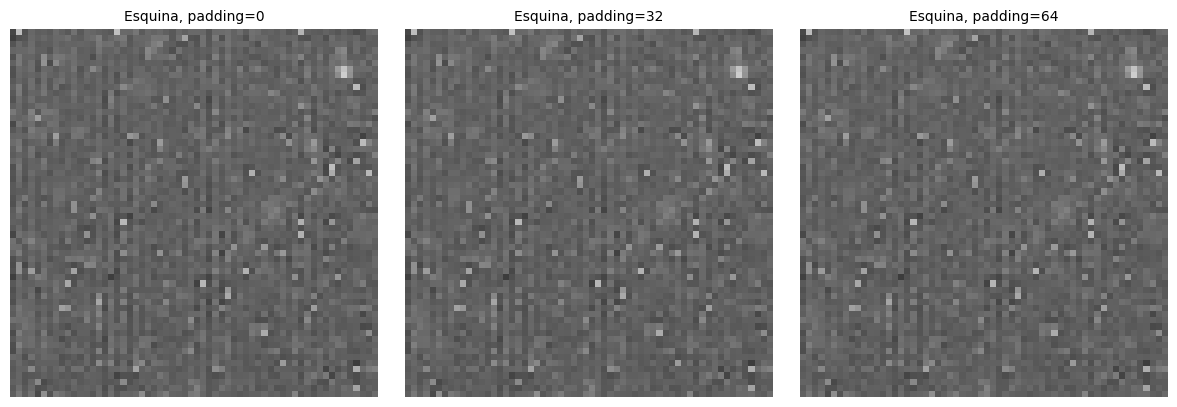

In [6]:
padding_cases = [(0, 0), (32, 32), (64, 64)]
padding_results = {}
for padding in padding_cases:
    filtered, F, H, FF = apply_notch(image, kind="gaussian", width=2.0, padding=padding)
    padding_results[padding] = filtered
    print(f"padding={padding}: std(diferencia)={np.std(image-filtered):.5f}, "
          f"media(abs(diferencia))={np.mean(np.abs(image-filtered)):.5f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, padding in zip(axes, padding_cases):
    ax.imshow(padding_results[padding], vmin=0, vmax=1)
    ax.set_title(f"Gaussiano, width=2, padding={padding[0]}")
    ax.axis("off")
plt.tight_layout(); plt.show()

# Comparacion ampliada de la esquina superior izquierda.
zoom = (slice(0, 60), slice(0, 60))
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, padding in zip(axes, padding_cases):
    ax.imshow(padding_results[padding][zoom], vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(f"Esquina, padding={padding[0]}")
    ax.axis("off")
plt.tight_layout(); plt.show()

### Seleccion del padding

La reflexion reduce el salto artificial entre la imagen y la zona agregada. Sin padding, el modelo periodico se encuentra con un borde brusco, lo que introduce energia adicional en el espectro y puede producir cambios visibles cerca de los bordes. Con 32 pixeles se separa el analisis del borde y se mantiene un costo razonable; 64 pixeles ofrece una extension mayor, pero no muestra una mejora proporcional en este caso. Por eso se usa `padding=(32, 32)` en la configuracion final.

## 6. Configuracion final y valores complejos

La configuracion elegida busca eliminar el patron sin borrar detalles: notch Gaussiano, `width=2` y padding reflexivo de 32 pixeles. La siguiente celda extrae una frecuencia afectada para verificar explicitamente la multiplicacion compleja `H(u,v)F(u,v)`.

Frecuencia relativa consultada: (u,v)=(1088,0)
F antes = -3.330183e+02 + 2.630324e+04j
H aplicado = 0.000000e+00
F despu?s = -0.000000e+00 + 0.000000e+00j
Comprobaci?n |F despu?s - H*F antes| = 0.000e+00


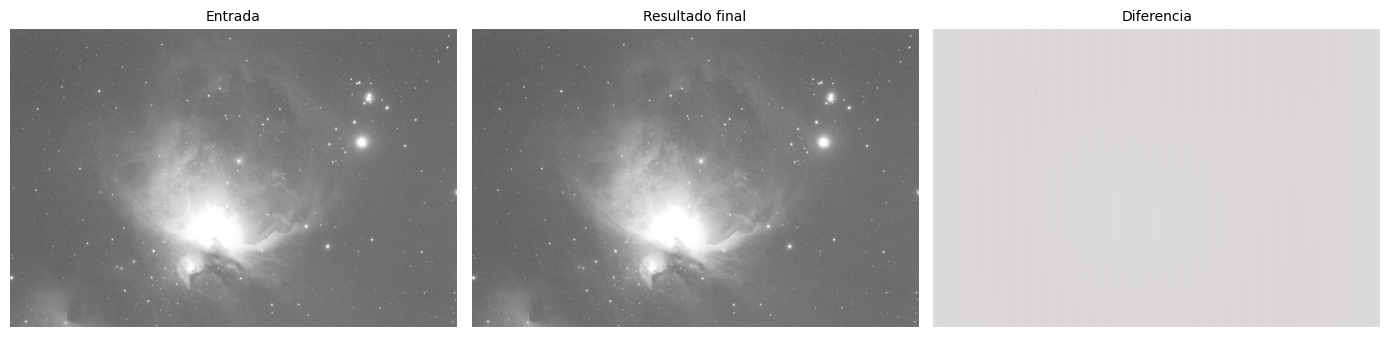

In [7]:
FINAL_KIND = "gaussian"
FINAL_WIDTH = 2.0
FINAL_PADDING = (32, 32)
final_image, F_final, H_final, FF_final = apply_notch(
    image, kind=FINAL_KIND, width=FINAL_WIDTH, padding=FINAL_PADDING
)

# El espectro esta centrado, se consulta el primer notch y su posicion simetrica.
py, px = FINAL_PADDING
shape_pad = (image.shape[0] + 2*py, image.shape[1] + 2*px)
cy, cx = np.array(shape_pad) // 2
u0, v0 = scaled_notch_pairs(image.shape, FINAL_PADDING)[0]
row, col = cy + v0, cx + u0
complex_before = F_final[row, col]
h_value = H_final[row, col]
complex_after = FF_final[row, col]
print(f"Frecuencia relativa consultada: (u,v)=({u0},{v0})")
print(f"F antes = {complex_before.real:.6e} + {complex_before.imag:.6e}j")
print(f"H aplicado = {h_value:.6e}")
print(f"F despu?s = {complex_after.real:.6e} + {complex_after.imag:.6e}j")
print(f"Comprobaci?n |F despu?s - H*F antes| = {abs(complex_after-h_value*complex_before):.3e}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(image, vmin=0, vmax=1); axes[0].set_title("Entrada")
axes[1].imshow(final_image, vmin=0, vmax=1); axes[1].set_title("Resultado final")
axes[2].imshow(image-final_image, vmin=-0.18, vmax=0.18, cmap="coolwarm"); axes[2].set_title("Diferencia")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
